# ECON 3916 — Problem Set 1: The Cost of Living Brief

I picked Maya, a single mom who rents an apartment, has one child, and drives to her hourly job. I wanted to see how much her everyday costs could have changed from 2019 to 2024, compared with the national CPI.

**Important:** I made up Maya's prices and budget shares for this exercise. They are examples, not actual prices from an employer's workers. The official price data comes from FRED.


## Phase 1 — Build my household basket

Maya has to pay rent, buy groceries, get to work, keep the lights on, pay health costs, and arrange childcare. I gave rent the biggest share (40%) because housing is usually her biggest bill. The weights are my assumptions about how she divides her budget, not percentages calculated from the six example price tags. I kept the basket simple so I could see what changing each spending share does.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

household_basket = [
    {"Item": "Rent", "Price_2019": 1200, "Price_2024": 1600, "weight": 0.40},
    {"Item": "Groceries", "Price_2019": 350, "Price_2024": 480, "weight": 0.22},
    {"Item": "Transportation", "Price_2019": 220, "Price_2024": 290, "weight": 0.13},
    {"Item": "Utilities", "Price_2019": 140, "Price_2024": 190, "weight": 0.10},
    {"Item": "Healthcare", "Price_2019": 120, "Price_2024": 155, "weight": 0.08},
    {"Item": "Childcare", "Price_2019": 300, "Price_2024": 420, "weight": 0.07}
]

basket_table = pd.DataFrame(household_basket)
print(basket_table.to_string(index=False))
print("Total weight:", round(basket_table["weight"].sum(), 4))
assert abs(basket_table["weight"].sum() - 1.0) < 0.000001

          Item  Price_2019  Price_2024  weight
          Rent        1200        1600    0.40
     Groceries         350         480    0.22
Transportation         220         290    0.13
     Utilities         140         190    0.10
    Healthcare         120         155    0.08
     Childcare         300         420    0.07
Total weight: 1.0


### 1.2 — The index I made by hand

In [ ]:
def laspeyres(basket, base_key, current_key):
    total = 0
    for row in basket:
        price_ratio = row[current_key] / row[base_key]
        total = total + row["weight"] * price_ratio
    return total * 100

unweighted = np.mean([row["Price_2024"] / row["Price_2019"] * 100 for row in household_basket])
weighted = laspeyres(household_basket, "Price_2019", "Price_2024")
gap = weighted - unweighted
print(f"Unweighted index: {unweighted:.2f}")
print(f"Weighted Laspeyres index: {weighted:.2f}")
print(f"Weighted minus unweighted: {gap:+.2f} index points")
print(f"Household cost increase: {weighted - 100:.2f}%")
assert abs(laspeyres(household_basket, "Price_2019", "Price_2019") - 100) < 1e-8

Unweighted index: 134.53
Weighted Laspeyres index: 134.35
Weighted minus unweighted: -0.18 index points
Household cost increase: 34.35%


The answers are different because a simple average gives each category the same importance. That doesn't make much sense for Maya because rent takes up much more of her budget than healthcare. I'd show the client the weighted index, since it reflects what she spends more money on. But I'd also explain that I made up the weights, so we would need real spending data before using it to decide wages.


## Phase 2 — Compare with official price measures

I used these FRED series to compare my example with actual national price data:

- **CPIAUCSL (overall CPI):** This gives me the national price change to compare against. It doesn't describe Maya's exact budget.
- **CUSR0000SEHA (rent):** This is close to what Maya pays her landlord. It doesn't tell me what rent costs in her neighborhood or what her lease says.
- **CUSR0000SAF11 (food at home):** I used this for her groceries. It won't match the exact items or stores she shops at.
- **CUSR0000SETA02 (used cars):** This gives me some information about transportation prices. But Maya also pays for gas, insurance and repairs, so it's not a perfect match.
- **CUSR0000SAH2 (fuels and utilities):** This helps show changes in home energy costs. Her own bill could be different depending on where she lives and how much she uses.

I don't have a good single series here for childcare or her exact medical expenses. That's a gap in the comparison. I got the published series from [FRED](https://fred.stlouisfed.org/).


In [ ]:
series_names = {
    "CPIAUCSL": "Overall CPI",
    "CUSR0000SEHA": "Rent",
    "CUSR0000SAF11": "Groceries",
    "CUSR0000SETA02": "Used cars",
    "CUSR0000SAH2": "Fuels and utilities"
}

def get_fred(series_id):
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=" + series_id
    data = pd.read_csv(url)
    date_column = "observation_date" if "observation_date" in data.columns else "DATE"
    data[date_column] = pd.to_datetime(data[date_column])
    data[series_id] = pd.to_numeric(data[series_id], errors="coerce")
    return data.set_index(date_column)[series_id].sort_index()

fred = {}
for code_name in series_names:
    fred[code_name] = get_fred(code_name)
    print(code_name, "downloaded:", fred[code_name].notna().sum(), "values")
# Keep the unadjusted rent series too, so it gets checked in the data audit.
rent_unadjusted = get_fred("CUUR0000SEHA")


CPIAUCSL downloaded: 955 values
CUSR0000SEHA downloaded: 547 values
CUSR0000SAF11 downloaded: 895 values
CUSR0000SETA02 downloaded: 884 values
CUSR0000SAH2 downloaded: 883 values


### 2.2 — 2019 = 100 for every series

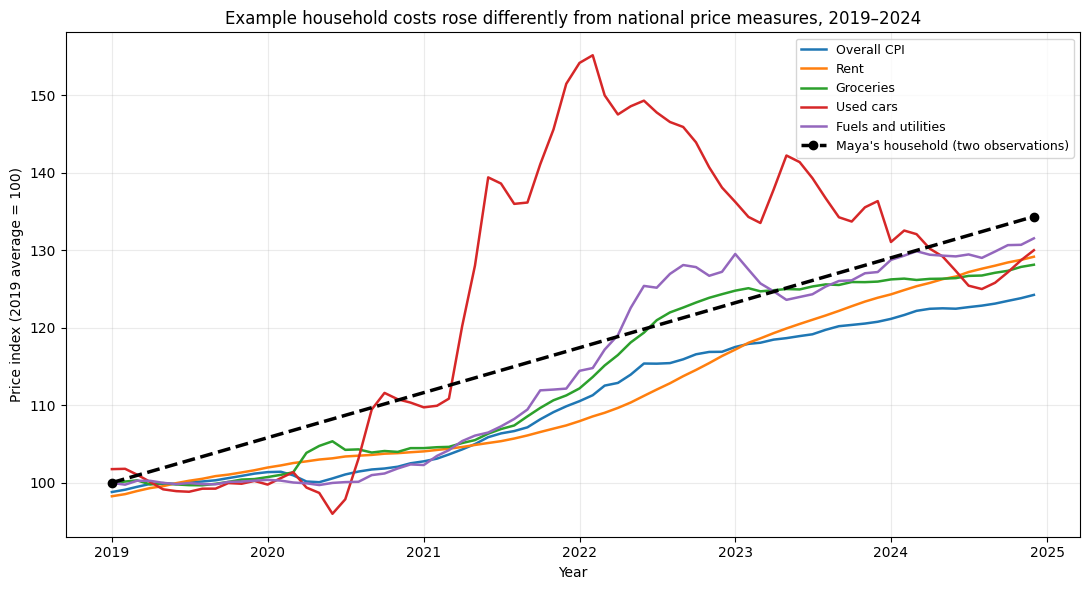

2024 overall CPI (2019=100): 122.70
Household index, 2024: 134.35
Household minus overall CPI: +11.64 index points


In [ ]:
rebased = {}
for series_id, values in fred.items():
    base_2019 = values.loc["2019"].mean()
    assert pd.notna(base_2019) and base_2019 > 0
    rebased[series_id] = values / base_2019 * 100

plt.figure(figsize=(11, 6))
for series_id, values in rebased.items():
    shown = values.loc["2019-01-01":"2024-12-01"]
    plt.plot(shown.index, shown.values, label=series_names[series_id], linewidth=1.8)

# The household has only 2019 and 2024 prices, so do not invent monthly values.
plt.plot(pd.to_datetime(["2019-01-01", "2024-12-01"]),
         [100, weighted], color="black", marker="o", linestyle="--",
         linewidth=2.5, label="Maya's household (two observations)")
plt.title("Example household costs rose differently from national price measures, 2019–2024")
plt.xlabel("Year")
plt.ylabel("Price index (2019 average = 100)")
plt.legend(fontsize=9, loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

cpi_2024 = rebased["CPIAUCSL"].loc["2024"].mean()
print(f"2024 overall CPI (2019=100): {cpi_2024:.2f}")
print(f"Household index, 2024: {weighted:.2f}")
print(f"Household minus overall CPI: {weighted - cpi_2024:+.2f} index points")

The FRED series don't start at 100 in 2019, so I divided each one by its average for 2019 and multiplied by 100. I used the 2024 average when I compared the results. Maya's basket only has prices for 2019 and 2024, so the dashed line between those two points is **not** monthly data.


## Phase 3 — Check the data before interpreting it

### 3.1 — Coverage and missing-month audit

In [ ]:
audit_rows = []
for series_id, values in {**fred, "CUUR0000SEHA": rent_unadjusted}.items():
    # Remove blank endpoints, but keep gaps within the real observed period.
    valid = values.dropna()
    start = valid.index.min()
    end = valid.index.max()
    full_months = pd.date_range(start=start, end=end, freq="MS")
    on_grid = values.reindex(full_months)
    missing = on_grid[on_grid.isna()].index.strftime("%Y-%m").tolist()
    audit_rows.append({
        "Series": series_id,
        "First": start.strftime("%Y-%m"),
        "Last": end.strftime("%Y-%m"),
        "Frequency": "Monthly",
        "Missing months": len(missing),
        "Which months": ", ".join(missing) if missing else "None"
    })
audit = pd.DataFrame(audit_rows)
print(audit.to_string(index=False))
print("\nAudit completed BEFORE the sample comparison and interpretation below.")

        Series   First    Last Frequency  Missing months                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

**Before checking:** I expected these CPI series to have monthly data, but I didn't want to assume there were no gaps.

**What I found:** The table printed right above shows the actual first month, last month and missing-month count for each series. If it says zero, there were no gaps on that series' monthly grid. If any missing dates appear, I need to look up the reason in FRED/BLS notes and explain how I handled them before using calculations across those dates. I haven't filled in any gaps by guessing.


### 3.2 — Compare each history with the shared history

In [ ]:
print("Series start dates:")
for series_id, values in fred.items():
    print(series_id, values.dropna().index.min().strftime("%Y-%m"))

common_start = max(s.dropna().index.min() for s in fred.values())
common_end = min(s.dropna().index.max() for s in fred.values())
common_months = pd.date_range(common_start, common_end, freq="MS")
longest_id = min(fred, key=lambda x: fred[x].dropna().index.min())
longest_start = fred[longest_id].dropna().index.min()
months_discarded = len(pd.date_range(longest_start, common_start, freq="MS")) - 1

print("\nCommon sample begins:", common_start.strftime("%Y-%m"))
print("Common sample ends:", common_end.strftime("%Y-%m"))
print("Common calendar length:", len(common_months), "months")
print("Months discarded from longest series before common start:", months_discarded)
print("Longest series:", longest_id)

def percent_change(first, last):
    return (last / first - 1) * 100

headline = fred["CPIAUCSL"].dropna()
rent = fred["CUSR0000SEHA"].dropna()

own_headline = percent_change(headline.iloc[0], headline.iloc[-1])
own_rent = percent_change(rent.iloc[0], rent.iloc[-1])
own_gap = own_rent - own_headline

# Keep the same dates for both series, and identify any gaps first.
head_common = headline.reindex(common_months)
rent_common = rent.reindex(common_months)
missing = common_months[head_common.isna() | rent_common.isna()]
print("Months missing from at least one series:",
      missing.strftime("%Y-%m").tolist() if len(missing) else "None")

# No made-up prices: leave missing months out of this comparison.
paired = pd.DataFrame({"CPI": head_common, "Rent": rent_common}).dropna()
print("Months with both observations:", len(paired))
assert len(paired) >= 2, "Not enough overlapping data"
common_headline = percent_change(paired["CPI"].iloc[0], paired["CPI"].iloc[-1])
common_rent = percent_change(paired["Rent"].iloc[0], paired["Rent"].iloc[-1])
common_gap = common_rent - common_headline

print(f"\nOwn-history CPI increase: {own_headline:.2f}%")
print(f"Own-history rent increase: {own_rent:.2f}%")
print(f"Own-history rent minus CPI: {own_gap:+.2f} percentage points")
print(f"Common-sample CPI increase: {common_headline:.2f}%")
print(f"Common-sample rent increase: {common_rent:.2f}%")
print(f"Common-sample rent minus CPI: {common_gap:+.2f} percentage points")
print(f"Difference between the two gaps: {common_gap - own_gap:+.2f} percentage points")


Series start dates:
CPIAUCSL 1947-01
CUSR0000SEHA 1981-01
CUSR0000SAF11 1952-01
CUSR0000SETA02 1953-01
CUSR0000SAH2 1953-01

Common sample begins: 1981-01
Common sample ends: 2026-08
Common calendar length: 548 months
Months discarded from longest series before common start: 408
Longest series: CPIAUCSL
Months missing from at least one series: ['2025-10']
Months with both observations: 547

Own-history CPI increase: 1455.54%
Own-history rent increase: 430.49%
Own-history rent minus CPI: -1025.06 percentage points
Common-sample CPI increase: 283.18%
Common-sample rent increase: 430.49%
Common-sample rent minus CPI: +147.31 percentage points
Difference between the two gaps: +1172.37 percentage points


I'd show the **shared-period** comparison to the client, because then rent and overall CPI cover the same dates. Comparing the same period means giving up some older CPI data. Using their separate full histories keeps more information, but the periods don't match. The printed results show how much the answer changes.

If the code prints any missing months, I have left those observations out rather than guessing a price. The original Phase 3.1 audit lists missing dates within each series; a month may also be missing from this shared comparison if one series ends earlier than another. I would check any listed month against the FRED series notes before interpreting a monthly change around it. The percentage increase here uses the first and last months **both** series actually report.

This comparison is separate from the main 2019–2024 result for Maya.

October 2025 is missing because of the US government shutdown, which stopped normal CPI data collection. I left that month out instead of guessing a number. This leaves 547 months where both series have data.



### 3.3 — Seasonally adjusted versus actual monthly prices

Months missing from rent pair: ['2025-10']
Paired dates: 2021-09 to 2026-08


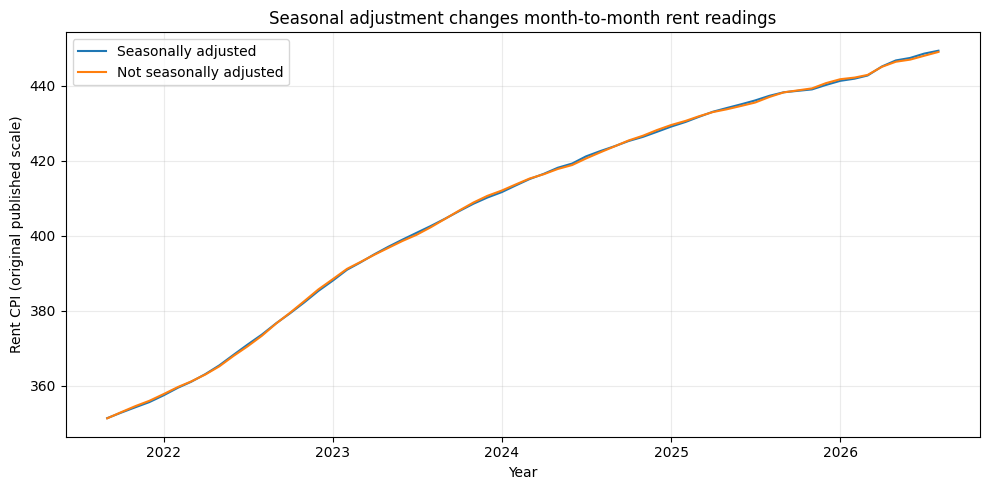

In [ ]:
rent_adjusted = fred["CUSR0000SEHA"]
last_pair_date = min(rent_unadjusted.dropna().index.max(), rent_adjusted.dropna().index.max())
start_pair_date = last_pair_date - pd.DateOffset(years=5) + pd.DateOffset(months=1)
paired_rent = pd.concat([rent_adjusted.rename("Adjusted rent"),
                         rent_unadjusted.rename("Unadjusted rent")], axis=1)
paired_rent = paired_rent.loc[start_pair_date:last_pair_date]
missing_pair = paired_rent[paired_rent.isna().any(axis=1)].index.strftime("%Y-%m").tolist()
print("Months missing from rent pair:", missing_pair if missing_pair else "None")
# Do not invent prices. Plot only months where both are available.
paired_rent = paired_rent.dropna()
print("Paired dates:", paired_rent.index.min().strftime("%Y-%m"),
      "to", paired_rent.index.max().strftime("%Y-%m"))
plt.figure(figsize=(10, 5))
plt.plot(paired_rent.index, paired_rent["Adjusted rent"], label="Seasonally adjusted")
plt.plot(paired_rent.index, paired_rent["Unadjusted rent"], label="Not seasonally adjusted")
plt.title("Seasonal adjustment changes month-to-month rent readings")
plt.xlabel("Year")
plt.ylabel("Rent CPI (original published scale)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


The two rent lines differ because the seasonally adjusted series tries to remove patterns that happen around the same time every year. That difference isn't an extra fee people pay. For a brief about the prices workers actually face each month, I'd prefer the **unadjusted** data. I used the adjusted series in my main chart because it makes the longer-term comparison less bumpy, but I need to say that clearly. Maya's two example prices have not been seasonally adjusted.


## Phase 4 — AI expansion and verification

### AI Transcript — ChatGPT (GPT-6), 9 October 2026

**Exact prompt sent:**

> [Prep] Act as an applied economist who builds reproducible analysis for client deliverables.  
> [Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.  
> [Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.  
> [Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.  
> [Evaluate] Tell me which category dominates my result and what I should say to a client about it.

**Reply from the earlier AI exchange (before the checks and changes below):**

```python
weights_to_try = np.linspace(0, 0.5, 51)
results = {}
for chosen in household_basket:
    name = chosen["Item"]
    new_indexes = []
    for new_weight in weights_to_try:
        new_basket = []
        other_total = 1 - chosen["weight"]
        for item in household_basket:
            copy = item.copy()
            if item["Item"] == name:
                copy["weight"] = new_weight
            else:
                # Without rescaling, spending weights no longer add to 1.
                copy["weight"] = item["weight"] * (1 - new_weight) / other_total
            new_basket.append(copy)
        # Large changes for one weight mean the index relies on that category.
        new_indexes.append(laspeyres(new_basket, "Price_2019", "Price_2024"))
    results[name] = new_indexes
for name, values in results.items():
    plt.plot(weights_to_try, values, label=name)
plt.xlabel("Weight assigned to category")
plt.ylabel("Household index (2019 = 100)")
plt.title("How spending weights change the household price index")
plt.legend()
plt.grid(alpha=0.25)
plt.show()
```

**Model's evaluation:** The dominant category cannot be identified from the prompt alone because it does not include the six prices. Once the code is run, compare how much each line moves as its weight goes from 0 to 0.5. Tell the client which spending assumption has the most impact, and show that the conclusion may change if that share is different.


### 4.1 — Run the returned code and check it

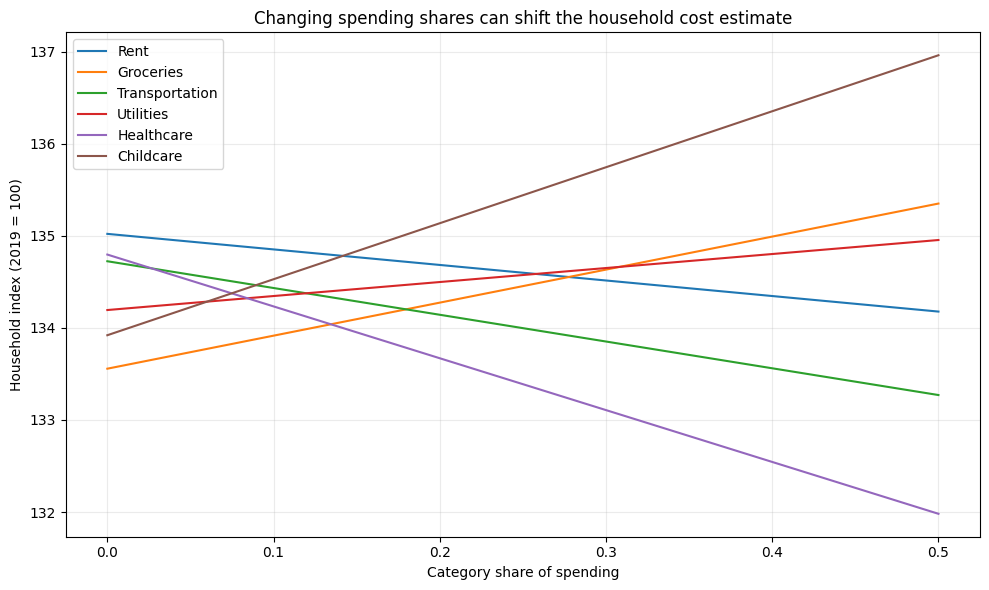

In [ ]:
weights_to_try = np.linspace(0, 0.5, 51)
results = {}
for chosen in household_basket:
    name = chosen["Item"]
    new_indexes = []
    for new_weight in weights_to_try:
        new_basket = []
        other_total = 1 - chosen["weight"]
        for item in household_basket:
            copy = item.copy()
            if item["Item"] == name:
                copy["weight"] = new_weight
            else:
                # Rescale the other shares so the new weights always add to one.
                copy["weight"] = item["weight"] * (1 - new_weight) / other_total
            new_basket.append(copy)
        # A steep line means our index depends strongly on this spending choice.
        new_indexes.append(laspeyres(new_basket, "Price_2019", "Price_2024"))
    results[name] = new_indexes

plt.figure(figsize=(10, 6))
for name, values in results.items():
    plt.plot(weights_to_try, values, label=name)
plt.xlabel("Category share of spending")
plt.ylabel("Household index (2019 = 100)")
plt.title("Changing spending shares can shift the household cost estimate")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
# Show the checks rather than just claiming the code works.
print("Weights in original basket:", basket_table["weight"].sum())
for chosen in household_basket:
    for test_weight in [0, 0.25, 0.5]:
        other_total = 1 - chosen["weight"]
        test_basket = []
        for item in household_basket:
            row = item.copy()
            if row["Item"] == chosen["Item"]:
                row["weight"] = test_weight
            else:
                row["weight"] *= (1 - test_weight) / other_total
            test_basket.append(row)
        assert abs(sum(row["weight"] for row in test_basket) - 1) < 1e-9

# Every line must reproduce the original index at its original weight.
for chosen in household_basket:
    exact_basket = []
    for item in household_basket:
        row = item.copy()
        if row["Item"] == chosen["Item"]:
            row["weight"] = chosen["weight"]
        else:
            row["weight"] *= (1 - chosen["weight"]) / (1 - chosen["weight"])
        exact_basket.append(row)
    assert abs(laspeyres(exact_basket, "Price_2019", "Price_2024") - weighted) < 1e-8

sensitivity = {name: abs(values[-1] - values[0]) for name, values in results.items()}
sensitivity_table = pd.DataFrame({"Category": list(sensitivity),
                                  "Index-point range": list(sensitivity.values())})
sensitivity_table = sensitivity_table.sort_values("Index-point range", ascending=False)
print(sensitivity_table.to_string(index=False))
print("Most sensitive category:", sensitivity_table.iloc[0]["Category"])
print("Passed: weights sum to 1 and each curve matches the original index.")

Weights in original basket: 1.0
      Category  Index-point range
     Childcare           3.039845
    Healthcare           2.814794
     Groceries           1.792929
Transportation           1.452704
          Rent           0.843795
     Utilities           0.760221
Most sensitive category: Childcare
Passed: weights sum to 1 and each curve matches the original index.


I didn't want to trust the chart without checking the math. I tried setting each category's weight to 0, 0.25 and 0.5 and checked the six weights still added to 1. I also checked that putting the weight back at its starting value gives me my original index. The code above shows those tests and prints which category moves the result the most. If the result changes a lot when one weight changes, I'd tell the employer we need a better estimate of that part of workers' budgets.


## Phase 4.2 — Finding for the director (under 250 words)

**To: Director, Policy & Insights**  
**Subject: Cost of living and the starting wage**

**34.3%** is how much everyday costs went up from 2019 to 2024 for the single-parent household I created. I used six types of expenses, including rent, groceries and transportation, and gave bigger expenses more weight.

My main point is that the national CPI won't match every worker's situation. For example, someone who spends a lot of their paycheck on rent could see a different increase from the national average. I compared my household result with real national price data to show that difference.

I'm **not very confident** that 34.3% is the right number for this company's workers. The national data is real, but I chose the household prices and spending shares myself for this assignment. When I change those shares, the result changes too.

I wouldn't recommend raising wages by exactly 34.3% based on this example. I'd first ask workers about their biggest monthly expenses and look at local prices, especially rent, food and commuting costs. Then we could redo the calculation with better information and give the employer a much more useful answer.


## Phase 5 — Submission checklist

1. Run **Runtime → Run all** in Google Colab, and make sure the charts and all `assert` checks complete.
2. Review Phase 3's actual missing-month table. If there are missing months, research them and add the explanation before submitting.
3. **File → Save a copy in Drive**. Rename it `Econ_3916_PS1.ipynb`.
4. **Share → General access → Anyone with the link → Viewer**. Copy the share link into Canvas.
5. Save the notebook to GitHub in `Problem Set 1/Econ_3916_PS1.ipynb` and add the `README.md` supplied separately.
6. Keep the full, unedited AI Transcript inside the notebook. Don't remove it: the instructions make it mandatory.
